# CNN con fotografías completas y comparación de modelos

La base única `data/base/` contiene las mismas 291 fotografías y etiquetas, con 22 grupos. La entrada de CNN conserva todo el encuadre y el fondo original, escala con proporciones fijas y rellena hasta 224×224. SVM y Random Forest usan las mismas 43 características extraídas dentro de las máscaras revisadas.

**Diseño previo a esta ejecución:** MobileNetV3 Small con extractor congelado y un nuevo clasificador. Se comparan 12 candidatos: cabezal lineal/MLP, exponente de peso de clase 0/0,5/1 y entrenamiento con/sin aumentos. Se mantienen máximo 120 épocas, mínimo de selección 12 y paciencia 15. La búsqueda usa hasta tres divisiones internas por grupos y los mismos tres bloques externos de semilla 42.

Se conservan como referencias históricas las predicciones de CNN simple y CNN con recortes, verificando identidades, etiquetas, máscaras y grupos. Son resultados de desarrollo, no una prueba independiente. Algunos originales muestran varios frutos: la etiqueta sigue correspondiendo al ejemplar revisado, lo que limita la interpretación de una predicción de toda la fotografía.

In [1]:
from pathlib import Path
import json
import sys

# Buscar la raíz por archivos versionados, sin exigir datos generados.
candidatos = [Path.cwd(), *Path.cwd().parents]
candidatos += [p / 'proyecto_estado_frutas' for p in candidatos.copy()]
PROYECTO = next((p for p in candidatos if (p / 'config/alcance_actual.json').is_file() and (p / 'src').is_dir()), None)
if PROYECTO is None:
    raise FileNotFoundError('Abrir el cuaderno desde la carpeta del proyecto o notebooks/.')
if str(PROYECTO) not in sys.path:
    sys.path.insert(0, str(PROYECTO))

import json
import pandas as pd
from IPython.display import Image, Markdown, display
from dataclasses import asdict
from src.data.base import cargar_base, verificar_imagenes
from src.models.cnn_calidad import candidatos_transferencia
from src.training.entrenar_modelos import ejecutar_comparacion

SALIDA = PROYECTO / 'experiments/results/comparacion_modelos'
CHECKPOINTS = PROYECTO / 'experiments/checkpoints/comparacion_modelos'
MAX_EPOCAS = 120
HILOS_CPU = 4
pd.set_option('display.max_columns', 12)
pd.set_option('display.precision', 4)
base, columnas, estado = cargar_base(PROYECTO)
verificar_imagenes(base)
print(f'Base: {len(base)} imágenes, {len(columnas)} características tradicionales y {base.grupo_particion.nunique()} grupos.')
print('SHA:', estado['sha_base'])
display(pd.DataFrame([asdict(c) for c in candidatos_transferencia(MAX_EPOCAS)]))

Base: 291 imágenes, 43 características tradicionales y 22 grupos.
SHA: 47bcd15916e6aa787ecaf1341cac98c31f392fd957499b07ca3e1592572528fc


,usar_aumentos,cabezal,potencia_peso,lr,weight_decay,dropout,max_epocas,min_epocas,paciencia
0,False,lineal,0.0,0.003,0.01,0.2,120,12,15
1,True,lineal,0.0,0.003,0.01,0.2,120,12,15
2,False,lineal,0.5,0.003,0.01,0.2,120,12,15
3,True,lineal,0.5,0.003,0.01,0.2,120,12,15
4,False,lineal,1.0,0.003,0.01,0.2,120,12,15
5,True,lineal,1.0,0.003,0.01,0.2,120,12,15
6,False,mlp,0.0,0.003,0.01,0.2,120,12,15
7,True,mlp,0.0,0.003,0.01,0.2,120,12,15
8,False,mlp,0.5,0.003,0.01,0.2,120,12,15
9,True,mlp,0.5,0.003,0.01,0.2,120,12,15


## Entrenamiento completo con el encuadre original

Las 291 entradas almacenadas para CNN ya contienen fotografías completas. No se calcula una caja para recortarlas, no se elimina el fondo ni se aplica CenterCrop. La normalización de canales usa las constantes de ImageNet. Las convoluciones y BatchNorm permanecen congeladas; el clasificador propio se entrena con AdamW, tasa 0,003, regularización 0,01 y dropout 0,2.

El cache incluye la vista original, espejo, giros de ±10° con expansión del lienzo y brillo 0,92. Los giros se vuelven a encajar conservando proporciones para no cortar esquinas. El uso de aumentos es un hiperparámetro seleccionado dentro del entrenamiento; la validación siempre usa la vista original. Las frecuencias de clase se calculan solo con los datos de entrenamiento de cada ajuste.

Los pesos actuales se guardan en la misma carpeta de comparación. La selección global por grupos fija los parámetros y épocas del prototipo final sobre toda la base. Las referencias históricas de recortes conservan su procedencia y no se presentan como entrenamiento con imágenes completas.

In [2]:
import os
if os.environ.get('FRUTAS_USAR_RESULTADOS') == '1':
    assert json.loads((SALIDA / 'configuracion_comparacion.json').read_text(encoding='utf-8'))['sha_base'] == estado['sha_base']
    tablas = {f.stem: pd.read_csv(f) for f in SALIDA.glob('*.csv')}
    print('Resultados del entrenamiento completo guardado, verificados contra la base actual.')
else:
    tablas = ejecutar_comparacion(PROYECTO, incluir_cnn=True, max_epocas_cnn=MAX_EPOCAS, hilos_cpu=HILOS_CPU)
display(tablas['metricas_globales'])
display(tablas['metricas_pliegues'])

Resultados del entrenamiento completo guardado, verificados contra la base actual.


,modelo,imagenes,exactitud,f1_macro,recall_macro,exactitud_peso_grupo,f1_macro_peso_grupo,recall_macro_peso_grupo
0,Referencia_mayoritaria,291,0.6907,0.2724,0.3333,0.5343,0.2322,0.3333
1,SVM_inicial,291,0.3952,0.2986,0.3653,0.4153,0.3675,0.3878
2,Random_Forest_inicial,291,0.5464,0.4288,0.4794,0.4472,0.4048,0.4376
3,SVM_ajustado,291,0.4467,0.3730,0.4135,0.4447,0.3739,0.3983
4,Random_Forest_ajustado,291,0.4433,0.3877,0.4297,0.4057,0.3665,0.4083
5,CNN_simple,291,0.2715,0.2367,0.3926,0.3658,0.3571,0.4134
6,CNN_recortada,291,0.7045,0.4725,0.5006,0.6278,0.5313,0.5235
7,CNN_transferencia,291,0.6735,0.4584,0.5052,0.4165,0.3758,0.4020


,modelo,pliegue,n_train,n_validacion,exactitud,f1_macro,recall_macro
0,Referencia_mayoritaria,1,182,109,0.9450,0.3239,0.3333
1,Referencia_mayoritaria,2,202,89,0.8539,0.3071,0.3333
2,Referencia_mayoritaria,3,198,93,0.2366,0.1275,0.3333
3,SVM_inicial,1,182,109,0.8257,0.3630,0.4515
4,SVM_inicial,2,202,89,0.1124,0.1438,0.2406
5,SVM_inicial,3,198,93,0.1613,0.1682,0.4186
6,Random_Forest_inicial,1,182,109,0.9450,0.4734,0.4935
7,Random_Forest_inicial,2,202,89,0.4607,0.4161,0.5142
8,Random_Forest_inicial,3,198,93,0.1613,0.2223,0.4288
9,SVM_ajustado,1,182,109,0.3119,0.2498,0.2702


## Comparación fuera del entrenamiento

Cada imagen tiene una predicción por modelo obtenida sin que su grupo estuviera en el entrenamiento correspondiente. F1 macro y recall macro dan el mismo peso a las tres calidades. La exactitud se interpreta junto con esas métricas porque el 69,1 % de las imágenes son buenas. Las métricas con peso por grupo exploran la influencia de las campañas grandes.

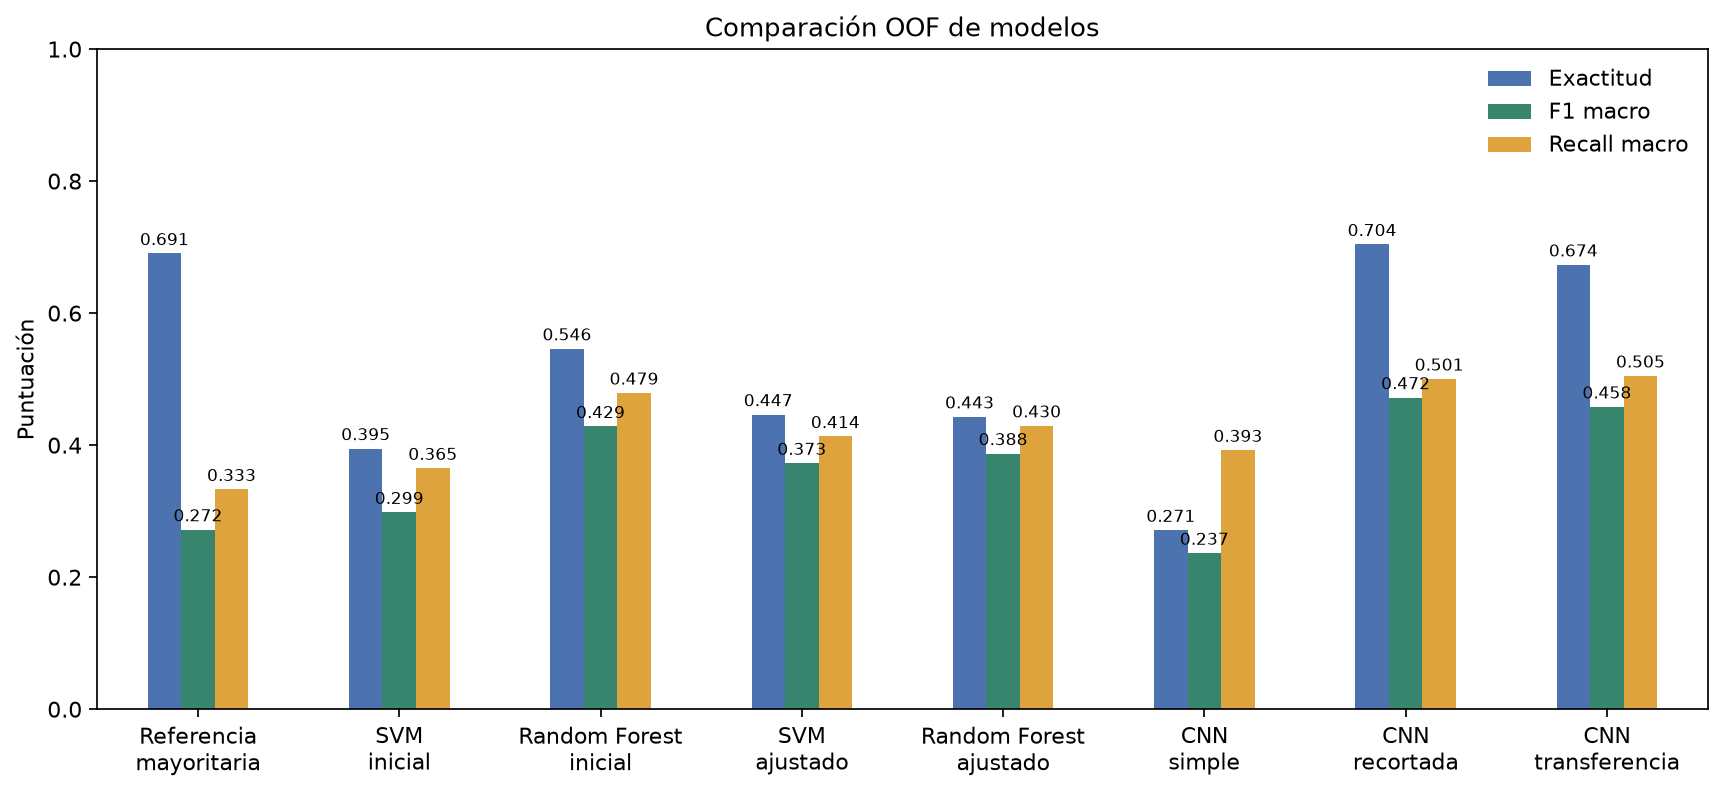

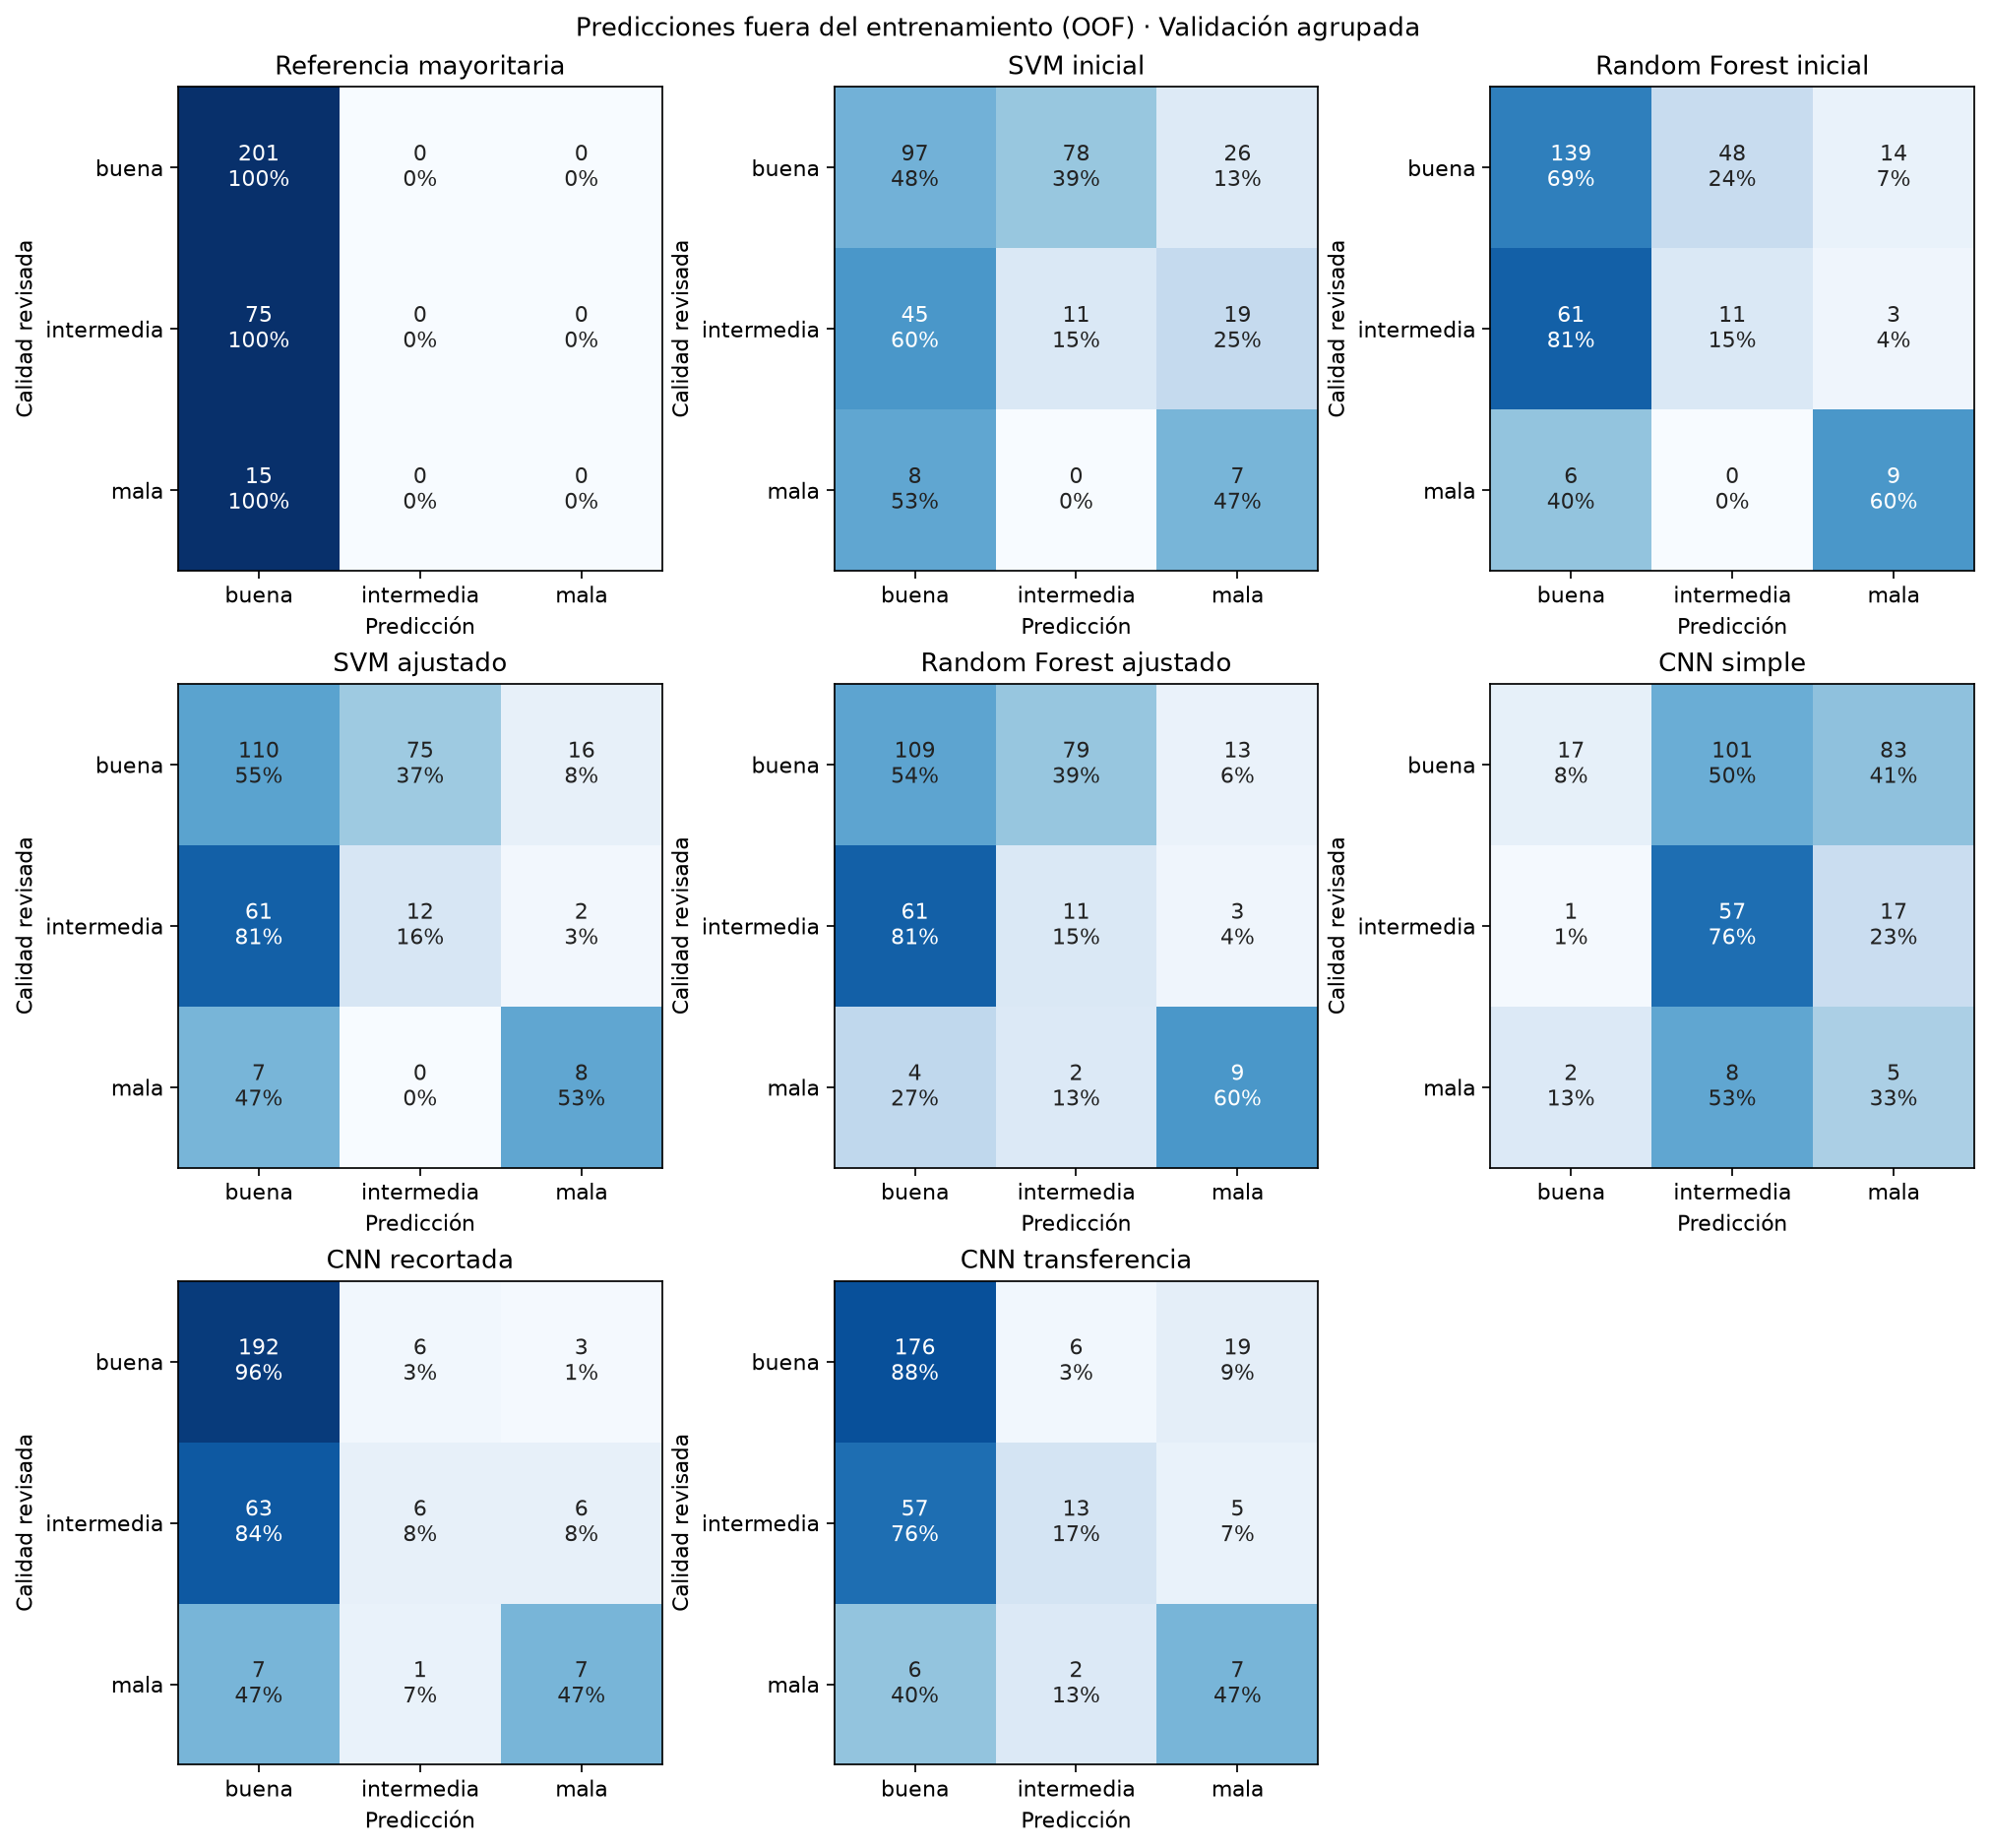

,modelo,calidad,imagenes,recall,f1
0,Referencia_mayoritaria,buena,201,1.0000,0.8171
1,Referencia_mayoritaria,intermedia,75,0.0000,0.0000
2,Referencia_mayoritaria,mala,15,0.0000,0.0000
3,SVM_inicial,buena,201,0.4826,0.5527
4,SVM_inicial,intermedia,75,0.1467,0.1341
5,SVM_inicial,mala,15,0.4667,0.2090
6,Random_Forest_inicial,buena,201,0.6915,0.6830
7,Random_Forest_inicial,intermedia,75,0.1467,0.1642
8,Random_Forest_inicial,mala,15,0.6000,0.4390
9,SVM_ajustado,buena,201,0.5473,0.5805


,modelo,fruta,imagenes,exactitud,f1_macro,recall_macro
0,Referencia_mayoritaria,banano,83,0.0964,0.0586,0.3333
1,Referencia_mayoritaria,limon,77,0.9351,0.3221,0.3333
2,Referencia_mayoritaria,manzana,131,0.9237,0.3201,0.3333
3,SVM_inicial,banano,83,0.1687,0.1576,0.3012
4,SVM_inicial,limon,77,0.0519,0.0353,0.3426
5,SVM_inicial,manzana,131,0.7405,0.3727,0.4915
6,Random_Forest_inicial,banano,83,0.1566,0.2619,0.2845
7,Random_Forest_inicial,limon,77,0.4545,0.2347,0.4861
8,Random_Forest_inicial,manzana,131,0.8473,0.4538,0.5750
9,SVM_ajustado,banano,83,0.1807,0.2899,0.2571


,modelo,fuente,imagenes,exactitud,f1_macro,recall_macro
0,Referencia_mayoritaria,propia,25,0.6000,0.2500,0.3333
1,Referencia_mayoritaria,publica,245,0.7265,0.2805,0.3333
2,Referencia_mayoritaria,publica_kaggle,21,0.3810,0.1839,0.3333
3,SVM_inicial,propia,25,0.4800,0.4870,0.6528
4,SVM_inicial,publica,245,0.3918,0.2265,0.2046
5,SVM_inicial,publica_kaggle,21,0.3333,0.3119,0.3175
6,Random_Forest_inicial,propia,25,0.4800,0.5259,0.6528
7,Random_Forest_inicial,publica,245,0.5714,0.2795,0.2839
8,Random_Forest_inicial,publica_kaggle,21,0.3333,0.3257,0.3433
9,SVM_ajustado,propia,25,0.4800,0.3483,0.3639


In [3]:
display(Image(filename=str(SALIDA / 'comparacion_modelos.png')))
display(Image(filename=str(SALIDA / 'matrices_confusion.png')))
display(tablas['metricas_por_clase'])
display(tablas['metricas_por_fruta'])
display(tablas['metricas_por_fuente'])

## Aprendizaje y selección de parámetros

Las curvas siguientes muestran el entrenamiento de cada bloque externo. La evaluación externa se hace después de terminarlo. Las tablas de búsqueda contienen puntuaciones internas; no son puntuaciones adicionales de prueba. El prototipo final puede tener una configuración distinta de la elegida en cada bloque.

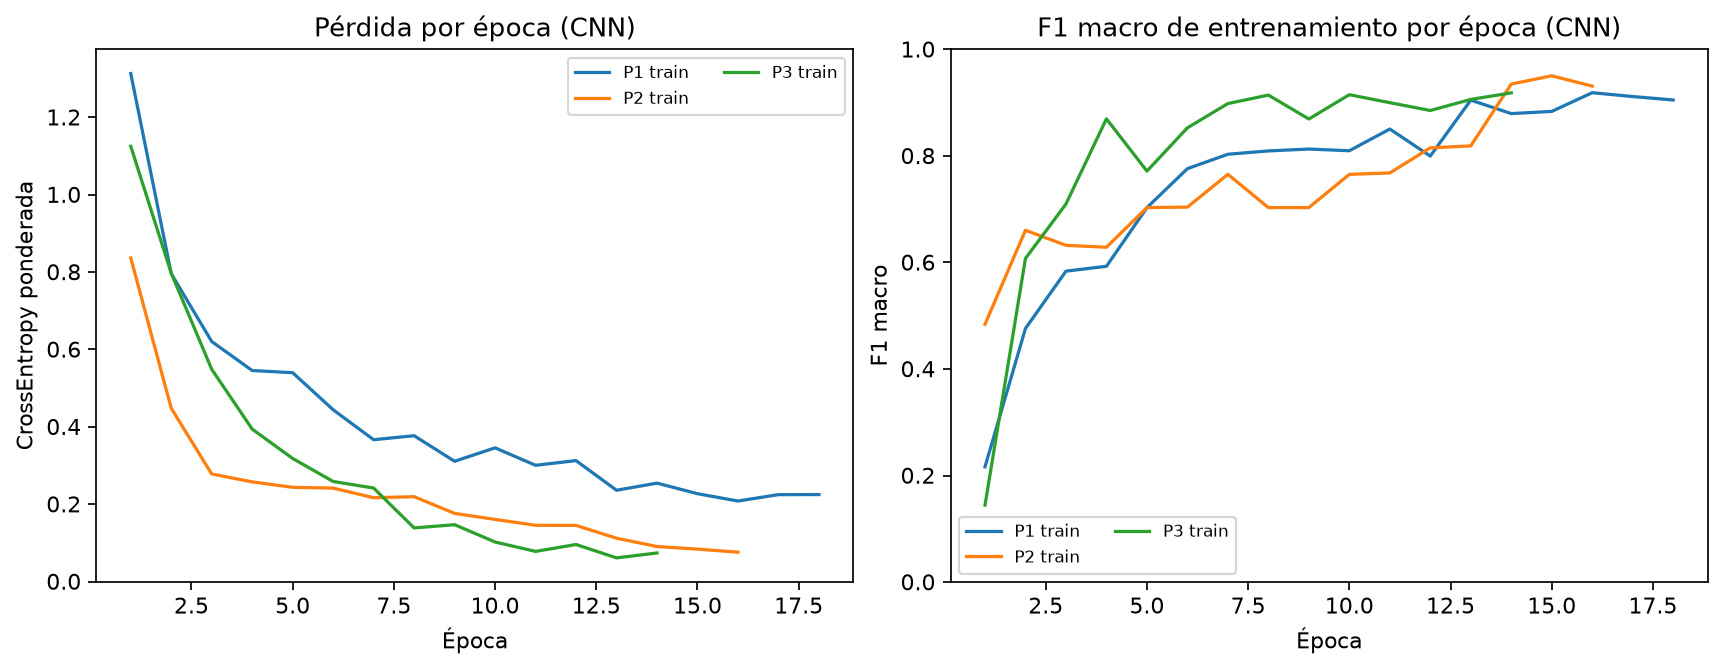

,exterior,usar_aumentos,cabezal,potencia_peso,lr,weight_decay,dropout,max_epocas,min_epocas,paciencia
0,1,True,lineal,0.5,0.003,0.01,0.2,18,12,15
1,2,False,lineal,0.0,0.003,0.01,0.2,16,12,15
2,3,False,mlp,1.0,0.003,0.01,0.2,14,12,15


,usar_aumentos,cabezal,potencia_peso,lr,weight_decay,dropout,...,min_epocas,paciencia,candidato,f1_macro_interno_medio,f1_macro_interno_std,epoca_media
0,True,lineal,0.5,0.003,0.01,0.2,...,12,15,4,0.5411,0.0088,20
1,False,lineal,1.0,0.003,0.01,0.2,...,12,15,5,0.5042,0.0320,12
2,False,lineal,0.5,0.003,0.01,0.2,...,12,15,3,0.5027,0.0337,14
3,True,mlp,1.0,0.003,0.01,0.2,...,12,15,12,0.4964,0.0742,15
4,True,lineal,1.0,0.003,0.01,0.2,...,12,15,6,0.4933,0.0434,21
5,False,lineal,0.0,0.003,0.01,0.2,...,12,15,1,0.4916,0.0679,34
6,False,mlp,1.0,0.003,0.01,0.2,...,12,15,11,0.4435,0.1260,14
7,False,mlp,0.5,0.003,0.01,0.2,...,12,15,9,0.4402,0.1271,16
8,True,mlp,0.5,0.003,0.01,0.2,...,12,15,10,0.4334,0.1367,19
9,False,mlp,0.0,0.003,0.01,0.2,...,12,15,7,0.4296,0.1189,35


Configuración final CNN: {'usar_aumentos': True, 'cabezal': 'lineal', 'potencia_peso': 0.5, 'lr': 0.003, 'weight_decay': 0.01, 'dropout': 0.2, 'max_epocas': 20, 'min_epocas': 12, 'paciencia': 15}
Dispositivo: cpu
Épocas finales: 20


In [4]:
display(Image(filename=str(SALIDA / 'curvas_entrenamiento_cnn.png')))
display(pd.read_csv(SALIDA / 'cnn_configuraciones_externas.csv'))
display(pd.read_csv(SALIDA / 'cnn_busqueda_global.csv'))
metadata = json.loads((SALIDA / 'configuracion_comparacion.json').read_text(encoding='utf-8'))
print('Configuración final CNN:', metadata['resumen_cnn']['mejor_config_global'])
print('Dispositivo:', metadata['resumen_cnn']['dispositivo'])
print('Épocas finales:', metadata['resumen_cnn']['epocas_finales'])

## Modelos guardados

La CNN final se guarda en la carpeta de comparación. Los modelos tradicionales conservan sus archivos de los cuadernos 06/07. Todas las referencias usan la misma huella de base. Cargar pesos permite preparar la inferencia; las métricas de comparación proceden de los modelos de cada bloque externo, no de predecir el entrenamiento con el modelo final.

In [5]:
import joblib
import torch
from src.models.cnn_calidad import CNNTransferencia, ConfigTransferencia, predecir_transferencia

rf = joblib.load(PROYECTO / 'experiments/checkpoints/modelos_tradicionales/random_forest.joblib')
paquete = torch.load(CHECKPOINTS / 'cnn_calidad.pt', map_location='cpu', weights_only=True)
assert rf['sha_base'] == paquete['sha_base'] == estado['sha_base']
assert paquete['arquitectura'] == 'mobilenet_v3_small_congelada'
assert paquete['preparacion_cnn'] == estado['entrada_cnn']
cnn = CNNTransferencia(ConfigTransferencia(**paquete['config']))
cnn.load_state_dict(paquete['state_dict'])
cnn.eval()
ejemplo, _ = predecir_transferencia(cnn, [Path(base.iloc[0].ruta_cnn)])
print('CNN recargada correctamente. Predicción de ejemplo:', ejemplo[0])
print('La recarga incluye todos los pesos; no necesita descargar ImageNet.')
print('Este ejemplo no se usa para calcular las métricas.')

CNN recargada correctamente. Predicción de ejemplo: intermedia
La recarga incluye todos los pesos; no necesita descargar ImageNet.
Este ejemplo no se usa para calcular las métricas.


## Resultado de la evaluación con fotografías completas

La siguiente celda calcula las diferencias de F1 macro respecto a los modelos tradicionales y las CNN históricas con recorte. Las métricas por calidad, fruta, fuente y grupo permiten interpretar el promedio. La combinación entre poca cobertura de intermedia y fotografías con mucho fondo limita la generalización.

Los parámetros y el uso de aumentos se seleccionan internamente. No se modifica la búsqueda al observar las puntuaciones externas. Los pesos de los tres bloques permiten reproducir sus probabilidades; el prototipo final se usa para inferencia, no para medir la calidad sobre su entrenamiento.

In [6]:
metricas = tablas['metricas_globales'].set_index('modelo')
cnn_f1 = metricas.loc['CNN_transferencia', 'f1_macro']
for nombre in ['CNN_simple', 'CNN_recortada', 'SVM_ajustado', 'Random_Forest_inicial']:
    if nombre in metricas.index:
        valor = metricas.loc[nombre, 'f1_macro']
        display(Markdown(f"**CNN actual frente a {nombre.replace('_', ' ')}:** F1 macro {cnn_f1:.3f} frente a {valor:.3f}; diferencia {cnn_f1-valor:+.3f}."))
display(tablas['metricas_por_clase'].query("modelo == 'CNN_transferencia'"))
display(Markdown('Esta comparación pertenece al desarrollo y conserva los grupos actuales. Una prueba final requiere capturas independientes reservadas antes de ajustar el procesamiento.'))

**CNN actual frente a CNN simple:** F1 macro 0.458 frente a 0.237; diferencia +0.222.

**CNN actual frente a CNN recortada:** F1 macro 0.458 frente a 0.472; diferencia -0.014.

**CNN actual frente a SVM ajustado:** F1 macro 0.458 frente a 0.373; diferencia +0.085.

**CNN actual frente a Random Forest inicial:** F1 macro 0.458 frente a 0.429; diferencia +0.030.

,modelo,calidad,imagenes,recall,f1
21,CNN_transferencia,buena,201,0.8756,0.8000
22,CNN_transferencia,intermedia,75,0.1733,0.2708
23,CNN_transferencia,mala,15,0.4667,0.3043


Esta comparación pertenece al desarrollo y conserva los grupos actuales. Una prueba final requiere capturas independientes reservadas antes de ajustar el procesamiento.

## Diagnóstico de la calidad intermedia

La clase intermedia contiene 70 bananos, 3 manzanas y 2 limones. Una sola campaña reúne 67 de las 75 imágenes. El tercer bloque evalúa esa campaña y entrena con solo 8 intermedias, incluidas 3 de banano. Las tablas siguientes permiten distinguir errores de la CNN, falta de cobertura y dependencia entre fotografías.

La galería revisa doce ejemplos de la campaña dominante, repartidos por probabilidad de intermedia, y las ocho intermedias restantes. Las etiquetas se mantienen; las predicciones y probabilidades no determinan una corrección de etiqueta. La revisión visual debe distinguir madurez/color de defectos superficiales, extensión de lesiones y arrugamiento. Las anotaciones actuales proceden de una revisión visual única, sin acuerdo entre anotadores medido.

Las galerías muestran la entrada vigente de fotografía completa. En los originales con varios frutos, el contorno revisado identifica el ejemplar al que corresponde la etiqueta; la CNN no recibe ese contorno como canal adicional.

In [7]:
from scripts.diagnosticar_intermedia import ejecutar, verificar

if os.environ.get('FRUTAS_USAR_RESULTADOS') == '1':
    diagnostico = {'grupos_intermedia': pd.read_csv(SALIDA / 'diagnostico_intermedia_por_grupo.csv'), 'cobertura': pd.read_csv(SALIDA / 'diagnostico_cobertura.csv'), 'resumen': json.loads((SALIDA / 'diagnostico_intermedia.json').read_text(encoding='utf-8')), 'metricas_alternativas': pd.read_csv(SALIDA / 'diagnostico_alternativas_metricas.csv')}
else:
    diagnostico = ejecutar(PROYECTO, comparar_alternativas=True)
display(diagnostico['grupos_intermedia'])
display(diagnostico['cobertura'].query("calidad == 'intermedia'"))
print('Confusión de intermedias:', diagnostico['resumen']['confusion_intermedia'])
print('Pliegues internos reales:', diagnostico['resumen']['pliegues_internos_por_exterior'])
print('Ajustes internos CNN:', diagnostico['resumen']['ajustes_internos_cnn'])

,grupo_particion,fruta,fuente,pliegue_validacion,imagenes,aciertos,prob_intermedia_media,recall_intermedia
0,03b4a5b0189f58cb,manzana,publica_kaggle,2,1,0,0.0368,0.0000
1,717c17ae4886b34b,manzana,publica_kaggle,1,2,0,0.0068,0.0000
2,94d8836cca0dfbac,limon,propia,2,2,0,0.0067,0.0000
3,b3614848dd857cd2,banano,publica,3,67,10,0.1962,0.1493
4,f5324b1335588796,banano,publica_kaggle,2,3,3,0.8899,1.0000


,pliegue,etapa,fruta,calidad,imagenes,grupos
1,1,entrenamiento,manzana,intermedia,1,1
4,1,entrenamiento,banano,intermedia,70,2
7,1,entrenamiento,limon,intermedia,2,1
10,1,validacion,manzana,intermedia,2,1
13,1,validacion,banano,intermedia,0,0
16,1,validacion,limon,intermedia,0,0
19,2,entrenamiento,manzana,intermedia,2,1
22,2,entrenamiento,banano,intermedia,67,1
25,2,entrenamiento,limon,intermedia,0,0
28,2,validacion,manzana,intermedia,1,1


Confusión de intermedias: {'buena': 57, 'intermedia': 13, 'mala': 5}
Pliegues internos reales: {'0': 3, '1': 3, '2': 2, '3': 3}
Ajustes internos CNN: 132


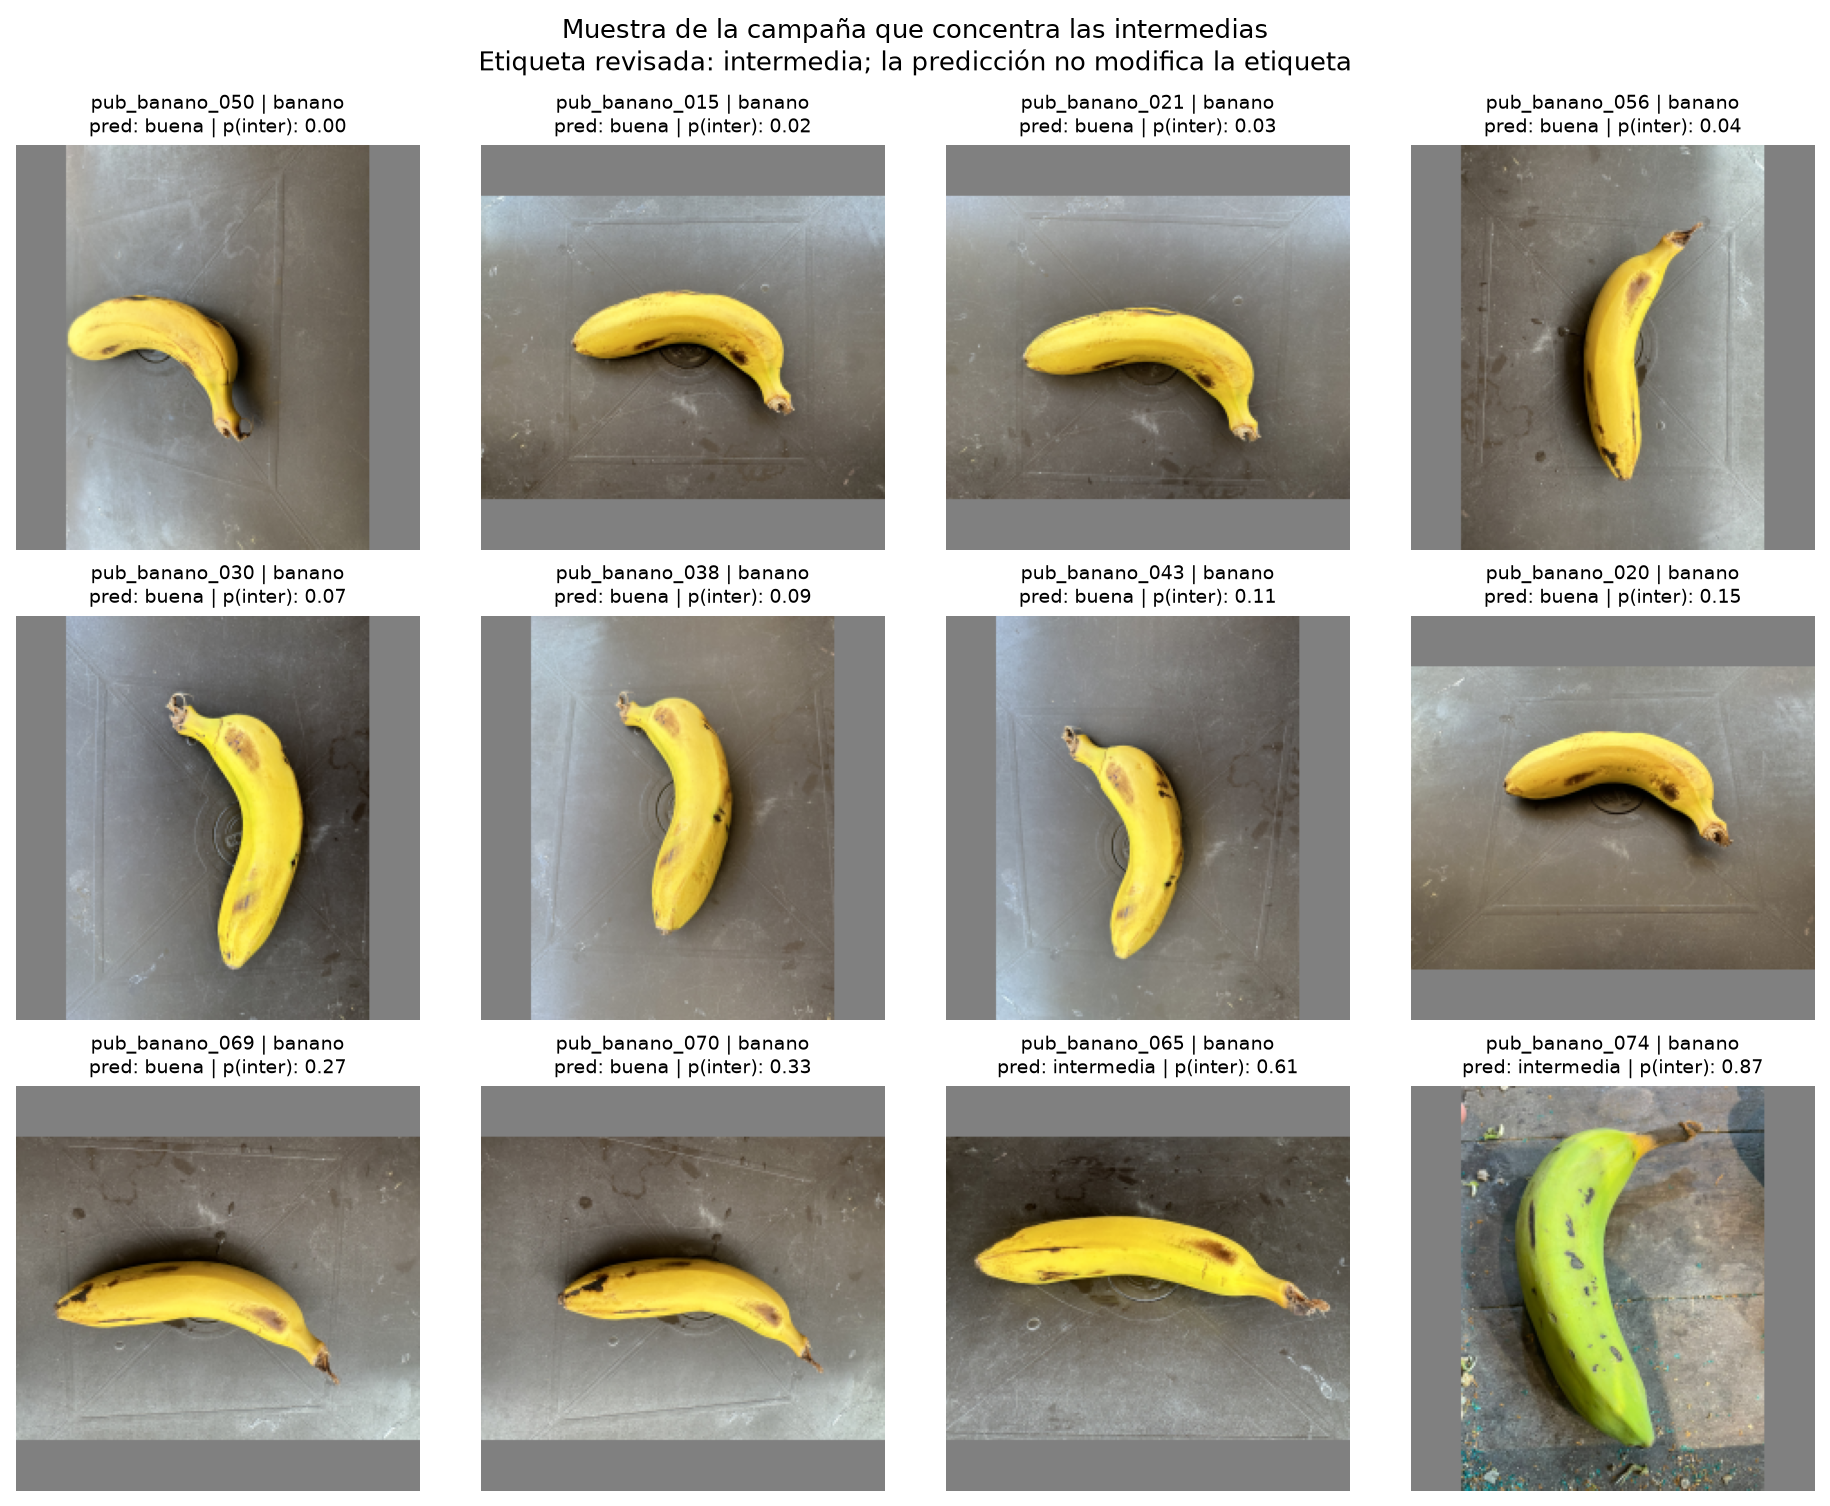

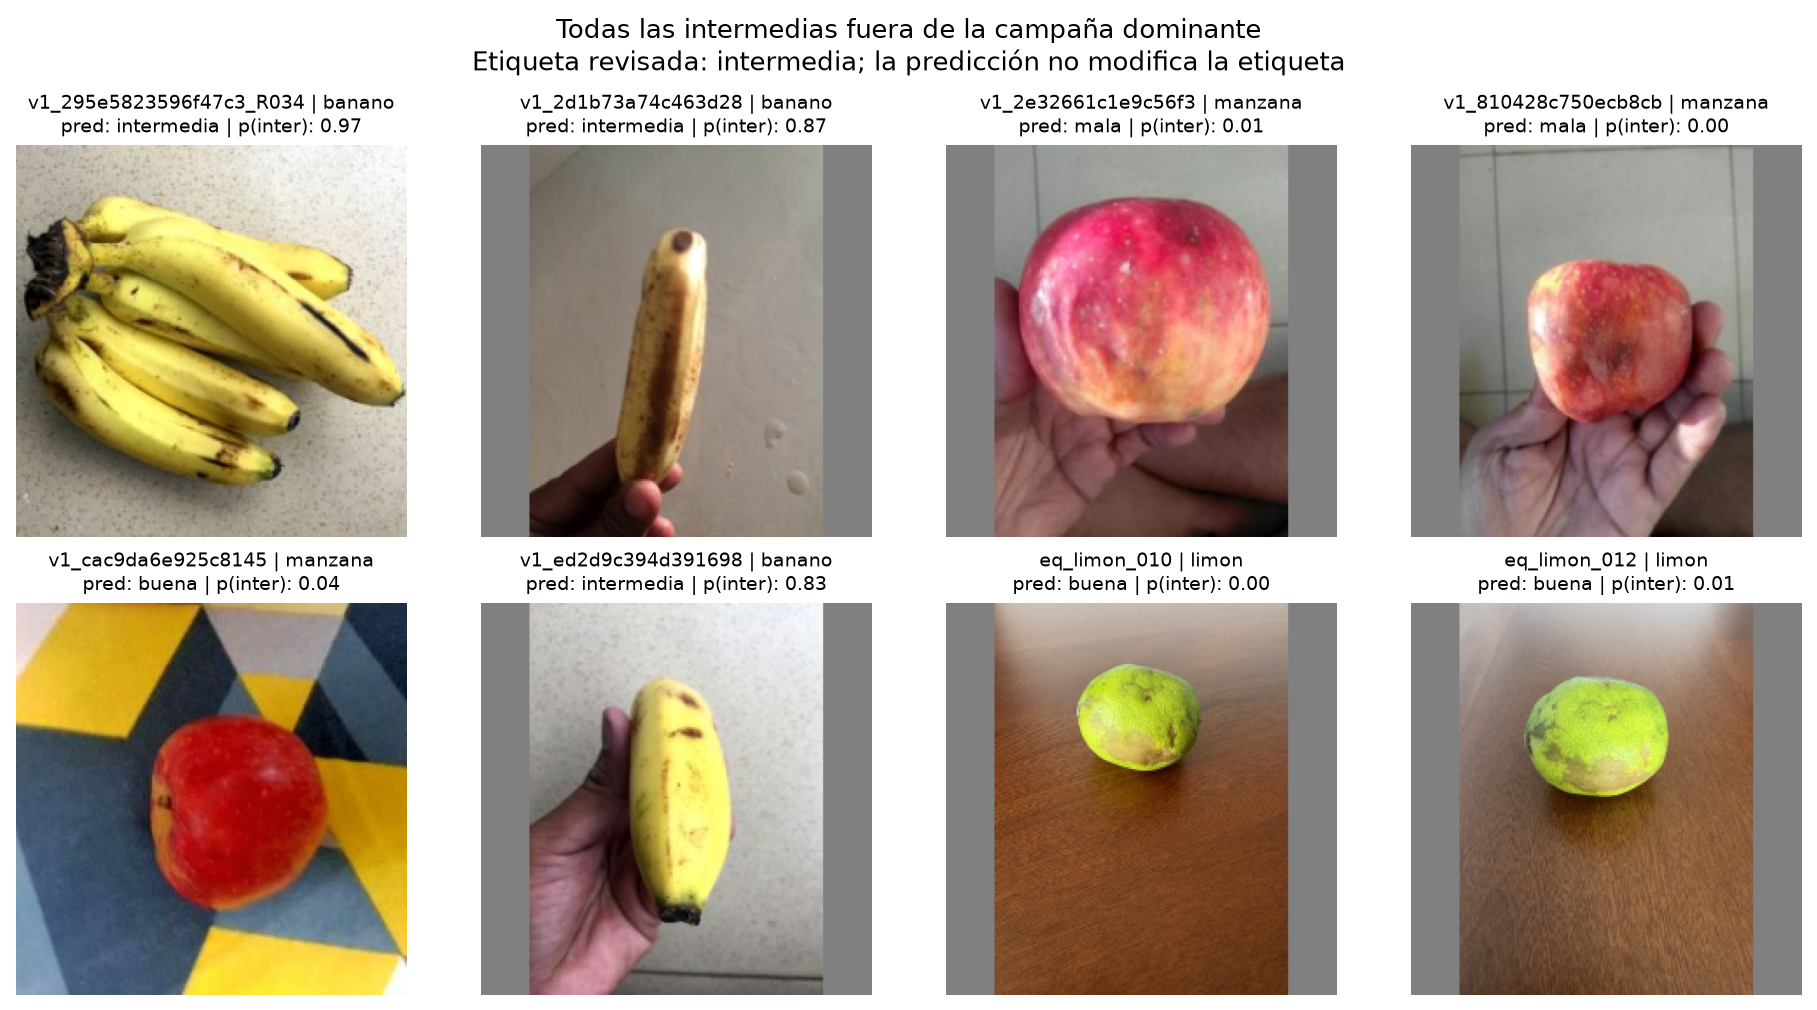

In [8]:
display(Image(filename=str(SALIDA / 'diagnostico_intermedia_campana.png'), width=1000))
display(Image(filename=str(SALIDA / 'diagnostico_intermedia_otros_grupos.png'), width=1000))

## Alternativas con la misma base

Se comparan regresión logística y SVM sobre los 576 rasgos de la CNN congelada sobre fotografías completas; Extra Trees y HistGradientBoosting usan las 43 características de color, textura y forma. La vista original es la entrada visual en este cribado, sin aumentos. StandardScaler se ajusta dentro de cada división para los modelos lineales/SVM. Boosting tiene desactivada la parada temprana automática para evitar una división aleatoria que mezcle grupos.

La búsqueda y la selección de parámetros usan hasta tres bloques internos agrupados, con las mismas semillas del flujo CNN. Los bloques externos son los mismos de todos los modelos. Los espacios se guardan antes de entrenar, y la selección maximiza F1 macro interno; no se ajusta un umbral sobre las predicciones externas. Este cribado amplía el informe existente sin reemplazar los pesos actuales de CNN. Sigue siendo desarrollo, no una prueba independiente.

Referencias: [regresión logística](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [SVM](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html), [Extra Trees](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.ExtraTreesClassifier.html) y [HistGradientBoosting](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html).

In [9]:
columnas_diagnostico = ['modelo', 'exactitud', 'f1_macro', 'precision_intermedia', 'recall_intermedia', 'f1_intermedia', 'aciertos_intermedia', 'predichas_intermedia', 'f1_macro_peso_grupo']
display(diagnostico['metricas_alternativas'][columnas_diagnostico].sort_values('f1_macro', ascending=False))
display(pd.read_csv(SALIDA / 'diagnostico_alternativas_bloques.csv'))
verificar(PROYECTO)

,modelo,exactitud,f1_macro,precision_intermedia,recall_intermedia,f1_intermedia,aciertos_intermedia,predichas_intermedia,f1_macro_peso_grupo
11,Gradient_Boosting,0.6495,0.4871,0.4130,0.2533,0.3140,19,46,0.4838
6,CNN_recortada,0.7045,0.4725,0.4615,0.0800,0.1364,6,13,0.5313
7,CNN_transferencia,0.6735,0.4584,0.6190,0.1733,0.2708,13,21,0.3758
9,SVM_CNN,0.6735,0.4297,0.4167,0.0667,0.1149,5,12,0.4316
2,Random_Forest_inicial,0.5464,0.4288,0.1864,0.1467,0.1642,11,59,0.4048
8,Logistica_CNN,0.6460,0.4000,0.3636,0.0533,0.0930,4,11,0.4212
4,Random_Forest_ajustado,0.4433,0.3877,0.1196,0.1467,0.1317,11,92,0.3665
3,SVM_ajustado,0.4467,0.3730,0.1379,0.1600,0.1481,12,87,0.3739
10,Extra_Trees,0.4227,0.3569,0.1099,0.1333,0.1205,10,91,0.3429
1,SVM_inicial,0.3952,0.2986,0.1236,0.1467,0.1341,11,89,0.3675


,modelo,exterior,exactitud,f1_macro,recall_macro,precision_intermedia,recall_intermedia,f1_intermedia,aciertos_intermedia,predichas_intermedia
0,Referencia_mayoritaria,1,0.9450,0.3239,0.3333,0.0000,0.0000,0.0000,0,0
1,Referencia_mayoritaria,2,0.8539,0.3071,0.3333,0.0000,0.0000,0.0000,0,0
2,Referencia_mayoritaria,3,0.2366,0.1275,0.3333,0.0000,0.0000,0.0000,0,0
3,SVM_inicial,1,0.8257,0.3630,0.4515,0.0000,0.0000,0.0000,0,0
4,SVM_inicial,2,0.1124,0.1438,0.2406,0.0411,0.5000,0.0759,3,73
5,SVM_inicial,3,0.1613,0.1682,0.4186,0.5000,0.1194,0.1928,8,16
6,Random_Forest_inicial,1,0.9450,0.4734,0.4935,0.0000,0.0000,0.0000,0,0
7,Random_Forest_inicial,2,0.4607,0.4161,0.5142,0.0889,0.6667,0.1569,4,45
8,Random_Forest_inicial,3,0.1613,0.2223,0.4288,0.5000,0.1045,0.1728,7,14
9,SVM_ajustado,1,0.3119,0.2498,0.2702,0.0000,0.0000,0.0000,0,64


Verificado diagnóstico: 3492 predicciones de 12 modelos; doce ajustes externos reproducidos.
Métricas, selección interna, referencias y separación de grupos correctas.


## Qué mejorar a partir del diagnóstico

Priorizar un criterio visual de calidad específico por fruta y una segunda revisión de los casos fronterizos, conservando el historial y sin cambiar etiquetas por conveniencia del modelo. Con las imágenes actuales pueden probarse fusión de rasgos CNN y características de máscara, ajuste interno de costes/umbrales, ponderación por grupo y un ajuste suave del último bloque convolucional. Cada experimento debe conservar las particiones externas y medir F1/precisión/recall de intermedia junto con el resultado global.

Las rotaciones y el sobremuestreo reutilizan la información existente; no aportan nuevos frutos o campañas. La clase intermedia representa calidad visual y la incertidumbre del clasificador se trata por separado. La diferencia de rendimiento entre bloques limita las conclusiones del promedio.